In [1]:
# Step 1: Import libraries and load the dataset

import pandas as pd
from pathlib import Path

# Locate the dataset
data_path = Path("../data/fulldata.csv")

if not data_path.exists():
    data_path = Path("data/fulldata.csv")

# Load the dataset
df = pd.read_csv(data_path)

# Display dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

# Display the first 5 rows
df.head()

Dataset Shape: (27425, 15)

Column Names:
['State', 'Strata', 'Sex', 'Age', 'Ethnic_Group', 'Citizenship', 'Marital_Status', 'Educational_Attainment', 'Highest_Certificate_Obtained', 'Field_of_Study', 'Occupation_2D', 'Industry_2D', 'G8_Total_salaries_and_wages', 'G14_Total_salaries_and_wages_includes_overtime', 'Weight']


,State,Strata,Sex,Age,Ethnic_Group,Citizenship,Marital_Status,Educational_Attainment,Highest_Certificate_Obtained,Field_of_Study,Occupation_2D,Industry_2D,G8_Total_salaries_and_wages,G14_Total_salaries_and_wages_includes_overtime,Weight
0,1,1,1,58,2,1,3,3,3,NaN,71,41,1520.0,1520.0,397.718282
1,12,2,1,64,1,1,2,4,4,NaN,12,46,3801.0,3801.0,48.357456
2,10,1,2,56,2,1,2,3,3,NaN,72,5,2930.0,2930.0,1225.996724
3,11,1,2,28,2,1,2,3,3,NaN,41,64,2971.0,2971.0,1201.312758
4,10,1,2,28,1,1,2,4,6,3.0,41,69,2034.0,2034.0,1460.804624


In [2]:
#  Identify categorical and numerical variables

# Categorical variables
categorical_cols = [
    'State',
    'Strata',
    'Sex',
    'Ethnic_Group',
    'Citizenship',
    'Marital_Status',
    'Educational_Attainment',
    'Highest_Certificate_Obtained',
    'Field_of_Study',
    'Occupation_2D',
    'Industry_2D'
]

# Numerical variables
numerical_cols = [
    'Age',
    'G8_Total_salaries_and_wages',
    'G14_Total_salaries_and_wages_includes_overtime',
    'Weight'
]

# Reload the dataset with appropriate data types
df = pd.read_csv(
    data_path,
    dtype={col: 'string' for col in categorical_cols}
)

# Convert numerical columns
for col in numerical_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Create a variable summary table
variable_summary = pd.DataFrame({
    'Data Type': df.dtypes.astype(str),
    'Missing Values': df.isnull().sum(),
    'Unique Values': df.nunique()
})

display(variable_summary)

,Data Type,Missing Values,Unique Values
State,string,0,16
Strata,string,0,2
Sex,string,0,2
Age,int64,0,50
Ethnic_Group,string,0,4
Citizenship,string,0,1
Marital_Status,string,0,4
Educational_Attainment,string,0,4
Highest_Certificate_Obtained,string,0,9
Field_of_Study,string,18109,9


In [3]:
# Step 3.1: Investigate missing values in Field_of_Study

# Calculate missing values by education level
missing_by_education = (
    df.groupby('Educational_Attainment')['Field_of_Study']
    .agg(
        Total='size',
        Non_Missing='count'
    )
)

# Calculate missing observations
missing_by_education['Missing'] = (
    missing_by_education['Total']
    - missing_by_education['Non_Missing']
)

# Calculate missing percentage
missing_by_education['Missing_Percentage'] = (
    missing_by_education['Missing']
    / missing_by_education['Total']
    * 100
)

# Display results
display(missing_by_education.round(2))

,Total,Non_Missing,Missing,Missing_Percentage
Educational_Attainment,,,,
1,237,0,237,100.00
2,1227,0,1227,100.00
3,15267,11,15256,99.93
4,10694,9305,1389,12.99


In [4]:
# Step 3.2: Investigate missingness by highest certificate
# Focus on tertiary education

tertiary_df = df[
    df['Educational_Attainment'] == '4'
]

# Group by highest certificate
missing_by_certificate = (
    tertiary_df.groupby('Highest_Certificate_Obtained')['Field_of_Study']
    .agg(
        Total='size',
        Non_Missing='count'
    )
)

# Calculate missing values
missing_by_certificate['Missing'] = (
    missing_by_certificate['Total']
    - missing_by_certificate['Non_Missing']
)

# Calculate missing percentage
missing_by_certificate['Missing_Percentage'] = (
    missing_by_certificate['Missing']
    / missing_by_certificate['Total']
    * 100
)

# Display results
display(missing_by_certificate.round(2))

,Total,Non_Missing,Missing,Missing_Percentage
Highest_Certificate_Obtained,,,,
3,267,32,235,88.01
4,1168,17,1151,98.54
5,611,611,0,0.00
6,3546,3543,3,0.08
7,5102,5102,0,0.00


In [5]:
# Step 3.3: Salary Distribution and Outlier Detection

# Define target variable
target = 'G14_Total_salaries_and_wages_includes_overtime'

# Salary descriptive statistics
salary = df[target]

print("Salary Descriptive Statistics:")
display(
    salary.describe(
        percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

# Check invalid salary values
print("\nMissing Salary:", salary.isna().sum())
print("Zero Salary:", (salary == 0).sum())
print("Negative Salary:", (salary < 0).sum())

# Detect potential outliers using IQR
Q1 = salary.quantile(0.25)
Q3 = salary.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (salary < lower_bound) |
    (salary > upper_bound)
]

print("\nIQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))
print("Potential Outliers:", len(outliers))
print(
    "Outlier Percentage:",
    round(len(outliers) / len(df) * 100, 2),
    "%"
)

Salary Descriptive Statistics:


count    27425.00
mean      3035.84
std       2458.07
min        308.00
25%       1484.00
50%       2117.00
75%       3941.00
90%       6137.00
95%       7599.40
99%      11101.19
max      80322.45
Name: G14_Total_salaries_and_wages_includes_overtime, dtype: float64


Missing Salary: 0
Zero Salary: 0
Negative Salary: 0

IQR: 2457.0
Lower Bound: -2201.5
Upper Bound: 7626.5
Potential Outliers: 1350
Outlier Percentage: 4.92 %


Mean Salary: 3035.84
Median Salary: 2117.0
Standard Deviation: 2458.07
Skewness: 4.24
Maximum Salary: 80322.45


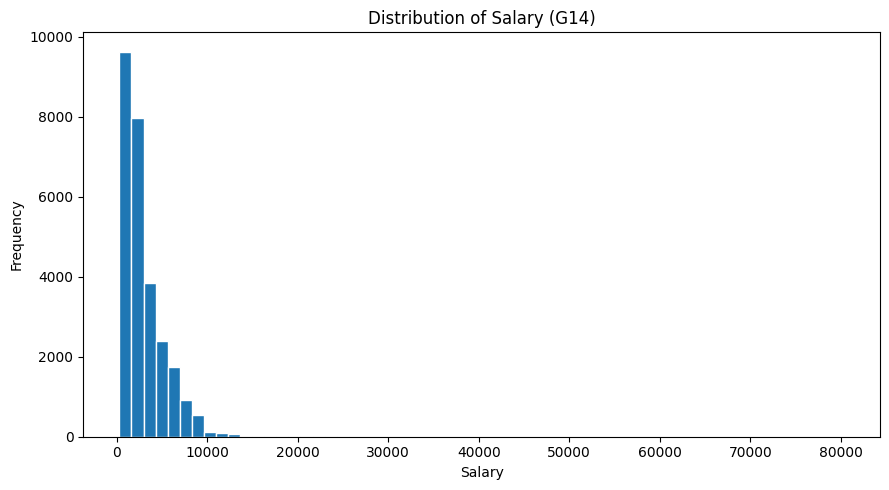

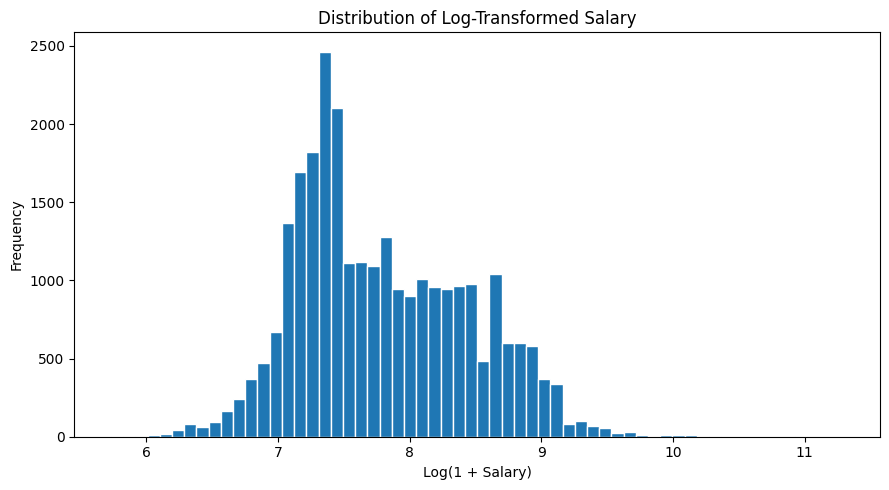

In [6]:
# Step 3.4: Salary Distribution and Skewness

import matplotlib.pyplot as plt
import numpy as np

target = 'G14_Total_salaries_and_wages_includes_overtime'

salary = df[target]

# Descriptive statistics
print("Mean Salary:", round(salary.mean(), 2))
print("Median Salary:", round(salary.median(), 2))
print("Standard Deviation:", round(salary.std(), 2))
print("Skewness:", round(salary.skew(), 2))
print("Maximum Salary:", round(salary.max(), 2))

# Original salary distribution
plt.figure(figsize=(9, 5))

plt.hist(salary, bins=60, edgecolor='white')

plt.title("Distribution of Salary (G14)")
plt.xlabel("Salary")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

# Log-transformed salary distribution
log_salary = np.log1p(salary)

plt.figure(figsize=(9, 5))

plt.hist(log_salary, bins=60, edgecolor='white')

plt.title("Distribution of Log-Transformed Salary")
plt.xlabel("Log(1 + Salary)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()